# Template und Temperatur

Zwei Dinge, die zwischen eurer Anwendung und dem Modell passieren: Das Chat-Template macht aus der Liste der Nachrichten einen einzigen Text, und die Temperatur formt die Verteilung, aus der das nächste Token gezogen wird. Beides mit Qwen2.5-0.5B-Instruct auf der CPU, eine GPU braucht es nicht.

1. Das Template: der Text, den das Modell wirklich bekommt
2. Modell laden
3. Die Verteilung für das nächste Token bei Temperatur 0,2, 1 und 2
4. Zehnmal ziehen

- **Pflicht:** Schritte 1 bis 4.
- **Zusatz:** ein eigener Systemprompt im Template.
- **Zeitbox:** 10 Minuten.

## Pflicht

### 1. Das Template

Für das Template braucht es nur den Tokenizer, das Modell noch nicht. Die Nachricht ist dieselbe wie bei der Temperatur auf der Folie: eine Frage mit wenigen guten Antworten.

In [ ]:
# Nur in Colab: Hilfsdateien und Daten aus dem Repo holen. Lokal tut die Zelle nichts.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    repo = "/content/ki-workshop-handson"
    if not os.path.exists(repo):
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/dprinz/ki-workshop-handson.git", repo], check=True)
    os.chdir(f"{repo}/sprachmodell")

In [1]:
from transformers import AutoTokenizer

MODELL = "Qwen/Qwen2.5-0.5B-Instruct"
tokenizer = AutoTokenizer.from_pretrained(MODELL)

nachrichten = [{"role": "user", "content": "Nenne eine Programmiersprache. Nur den Namen."}]
text = tokenizer.apply_chat_template(nachrichten, tokenize=False, add_generation_prompt=True)
print(text)

<|im_start|>system
You are Qwen, created by Alibaba Cloud. You are a helpful assistant.<|im_end|>
<|im_start|>user
Nenne eine Programmiersprache. Nur den Namen.<|im_end|>
<|im_start|>assistant



Drei Dinge fallen auf:

- Jede Nachricht steht zwischen `<|im_start|>` mit der Rolle und `<|im_end|>`.
- Oben steht eine System-Nachricht, die niemand geschickt hat. Das Template von Qwen2.5 setzt sie ein, wenn die erste Nachricht keine System-Nachricht ist; es ist derselbe Satz, den `ollama show qwen2.5:7b --system` zeigt.
- Am Ende steht eine offene Zeile `<|im_start|>assistant`. Die setzt `add_generation_prompt=True`, und dort setzt das Modell fort.

Die Markierungen sehen aus wie Text, sind aber je ein einziges Token mit eigener Nummer, mitten in derselben Folge wie die Nachricht:

In [2]:
ids = tokenizer(text).input_ids
print(len(ids), "Token, die ersten acht:")
for nummer in ids[:8]:
    print(f"{nummer:>8}  {tokenizer.decode(nummer)!r}")

41 Token, die ersten acht:
  151644  '<|im_start|>'
    8948  'system'
     198  '\n'
    2610  'You'
     525  ' are'
    1207  ' Q'
   16948  'wen'
      11  ','


### 2. Modell laden

In Colab rund 35 Sekunden: knapp 1 GB Download, dann Laden.

In [3]:
import torch
from transformers import AutoModelForCausalLM

from helfer import zeige_verteilungen

modell = AutoModelForCausalLM.from_pretrained(MODELL, dtype=torch.float32)

### 3. Die Verteilung für das nächste Token

Ein Vorwärtslauf liefert für jedes Token im Vokabular einen Logit. Die Temperatur teilt die Logits vor Softmax, wie in der Java-Zeile auf der Folie: `p[i] = Math.exp(logit[i] / T) / summe`.

151936 Logits, einer pro Token im Vokabular

T = 0.2:  Python 0.999, Java 0.001, C 0.000, JavaScript 0.000, PHP 0.000   Summe der Top-5: 1.000
T = 1.0:  Python 0.689, Java 0.158, C 0.023, JavaScript 0.016, PHP 0.009   Summe der Top-5: 0.895
T = 2.0:  Python 0.054, Java 0.026, C 0.010, JavaScript 0.008, PHP 0.006   Summe der Top-5: 0.104


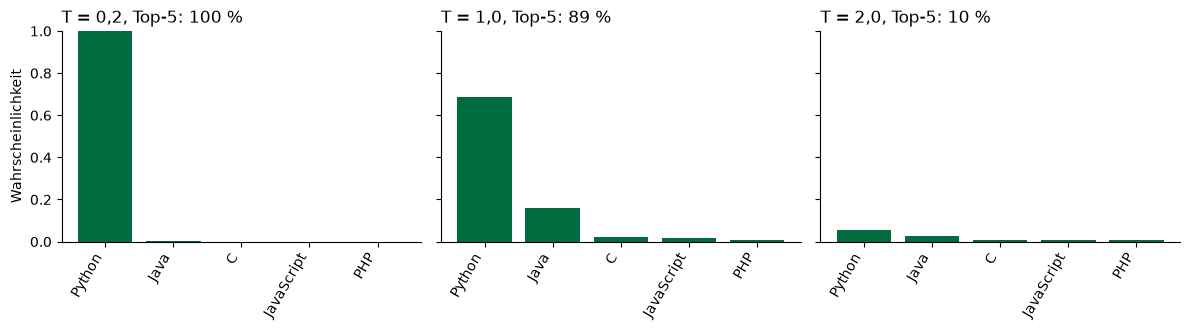

In [4]:
def naechstes_token(text):
    """Ein Vorwärtslauf: die Logits für das Token, das auf den Text folgt."""
    with torch.no_grad():
        return modell(**tokenizer(text, return_tensors="pt")).logits[0, -1]


def verteilungen_zeigen(logits, temperaturen=(0.2, 1.0, 2.0)):
    verteilungen = {}
    for T in temperaturen:
        p = torch.softmax(logits / T, dim=-1)
        werte, nummern = p.topk(5)
        top5 = ", ".join(f"{tokenizer.decode(int(n))} {w:.3f}" for w, n in zip(werte, nummern))
        print(f"T = {T}:  {top5}   Summe der Top-5: {werte.sum():.3f}")
        verteilungen[T] = p
    return verteilungen


logits = naechstes_token(text)
print(f"{len(logits)} Logits, einer pro Token im Vokabular\n")
verteilungen = verteilungen_zeigen(logits)
zeige_verteilungen(verteilungen, tokenizer)

Bei T = 0,2 ist die Verteilung so spitz, dass praktisch immer „Python“ kommt. Bei T = 1 ist es die Verteilung, die das Modell gelernt hat. Bei T = 2 liegt auf den fünf häufigsten Token zusammen nur noch rund ein Zehntel, der Rest verteilt sich auf den langen Schwanz des Vokabulars. Auf der CPU sollten eure Zahlen dieselben sein: Hier wird nichts gezogen, nur gerechnet.

Auf der Folie war es ein Base Model mit einem Satzanfang, hier ist es das Instruct-Modell mit einer Frage. Der Mechanismus ist derselbe.

### 4. Zehnmal ziehen

Jetzt wird gezogen, gewichtet zufällig nach der Verteilung, ohne Top-k und Top-p, nur mit der Temperatur.

In [5]:
for T, p in verteilungen.items():
    gezogen = torch.multinomial(p, num_samples=10, replacement=True)
    print(f"T = {T}:  " + "  ".join(repr(tokenizer.decode(int(n))) for n in gezogen))

T = 0.2:  'Python'  'Python'  'Python'  'Python'  'Python'  'Python'  'Python'  'Python'  'Python'  'Python'
T = 1.0:  'Python'  'Python'  'Python'  'Python'  'Python'  'Java'  'Python'  'Python'  'C'  'Python'
T = 2.0:  'ó'  ' Vik'  '_write'  'Z'  'MySQL'  ' appar'  ' giờ'  'Ruby'  'Follow'  'Fun'


Wie oft erwartet ihr „Python“ unter zehn Zügen bei T = 1, wie oft bei T = 2? Zählt nach und führt die Zelle noch zwei-, dreimal aus.

In [6]:
# @title Lösung (aufklappen)
python = tokenizer.encode("Python")[0]
for T, p in verteilungen.items():
    print(f"T = {T}: Python mit {p[python]:.3f}, also im Mittel {10 * p[python]:.1f} von 10 Zügen")

T = 0.2: Python mit 0.999, also im Mittel 10.0 von 10 Zügen
T = 1.0: Python mit 0.689, also im Mittel 6.9 von 10 Zügen
T = 2.0: Python mit 0.054, also im Mittel 0.5 von 10 Zügen


Bei T = 2 kommt Python im Mittel nur noch in einem von zwanzig Zügen. Rund neun von zehn Zügen landen ausserhalb der fünf häufigsten Token, oft auf Token, die mit der Frage nichts zu tun haben. Bei T = 0 würde ein Server immer das wahrscheinlichste Token nehmen, hier `logits.argmax()`. Das macht die Antwort wiederholbar, aber nicht richtiger.

## Zusatz: ein eigener Systemprompt

Setzt einen eigenen Systemprompt vor die Nachricht. Wo steht er im Template, und was ist mit dem Satz „You are Qwen …“ passiert? Wie ändert sich die Verteilung? Versucht, das Modell auf eine andere Sprache als Python zu bringen.

In [7]:
mein_system = "Du bist ein Java-Entwickler."

meine_nachrichten = [{"role": "system", "content": mein_system}] + nachrichten
mein_text = tokenizer.apply_chat_template(meine_nachrichten, tokenize=False, add_generation_prompt=True)
print(mein_text)

meine_verteilungen = verteilungen_zeigen(naechstes_token(mein_text))

<|im_start|>system
Du bist ein Java-Entwickler.<|im_end|>
<|im_start|>user
Nenne eine Programmiersprache. Nur den Namen.<|im_end|>
<|im_start|>assistant

T = 0.2:  Java 0.991, Python 0.008, C 0.001, Scala 0.000, Gro 0.000   Summe der Top-5: 1.000
T = 1.0:  Java 0.435, Python 0.166, C 0.109, Scala 0.056, Gro 0.049   Summe der Top-5: 0.816
T = 2.0:  Java 0.044, Python 0.027, C 0.022, Scala 0.016, Gro 0.015   Summe der Top-5: 0.125


In [8]:
# @title Lösung (aufklappen)
# Der eigene Systemprompt ersetzt den Standardsatz. Er verschiebt die Verteilung, garantiert aber nichts:
# Bei "nur in Kotlin" bleibt Java vorn, und Kotlin beginnt mit dem Token "K", weil der Tokenizer
# das Wort in zwei Token zerlegt. Erst der Systemprompt unten bringt Java bei T = 1 auf rund drei Viertel.
for loesung_system in ["Du programmierst nur in Kotlin.", "Antworte immer mit einer JVM-Sprache."]:
    loesung_text = tokenizer.apply_chat_template(
        [{"role": "system", "content": loesung_system}] + nachrichten, tokenize=False, add_generation_prompt=True
    )
    print(loesung_system)
    loesung_verteilungen = verteilungen_zeigen(naechstes_token(loesung_text))
    print()
print("Kotlin in Token:", [tokenizer.decode(n) for n in tokenizer.encode("Kotlin")])

Du programmierst nur in Kotlin.


T = 0.2:  Java 0.900, K 0.089, Scala 0.009, Python 0.002, JavaScript 0.000   Summe der Top-5: 1.000
T = 1.0:  Java 0.322, K 0.203, Scala 0.128, Python 0.090, JavaScript 0.052   Summe der Top-5: 0.795
T = 2.0:  Java 0.035, K 0.028, Scala 0.022, Python 0.018, JavaScript 0.014   Summe der Top-5: 0.117

Antworte immer mit einer JVM-Sprache.


T = 0.2:  Java 1.000, Scala 0.000, J 0.000, Gro 0.000, E 0.000   Summe der Top-5: 1.000
T = 1.0:  Java 0.739, Scala 0.068, J 0.038, Gro 0.037, E 0.027   Summe der Top-5: 0.909
T = 2.0:  Java 0.074, Scala 0.022, J 0.017, Gro 0.016, E 0.014   Summe der Top-5: 0.143

Kotlin in Token: ['K', 'otlin']
